## Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import Cloud38Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import matplotlib.pyplot as plt
import numpy as np

## Visualize images and masks

Total number of patches: 8400


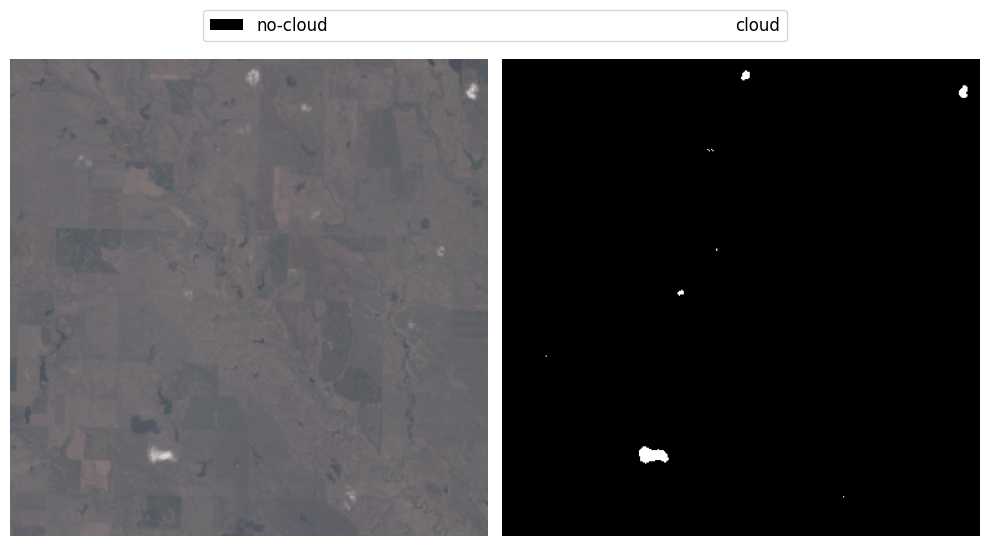

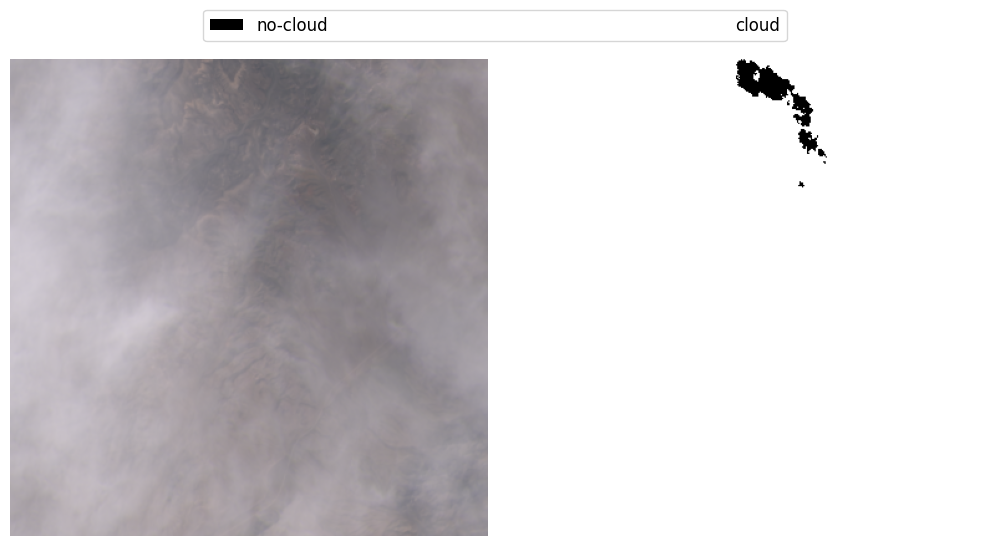

2025-07-16 08:29:52,685 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


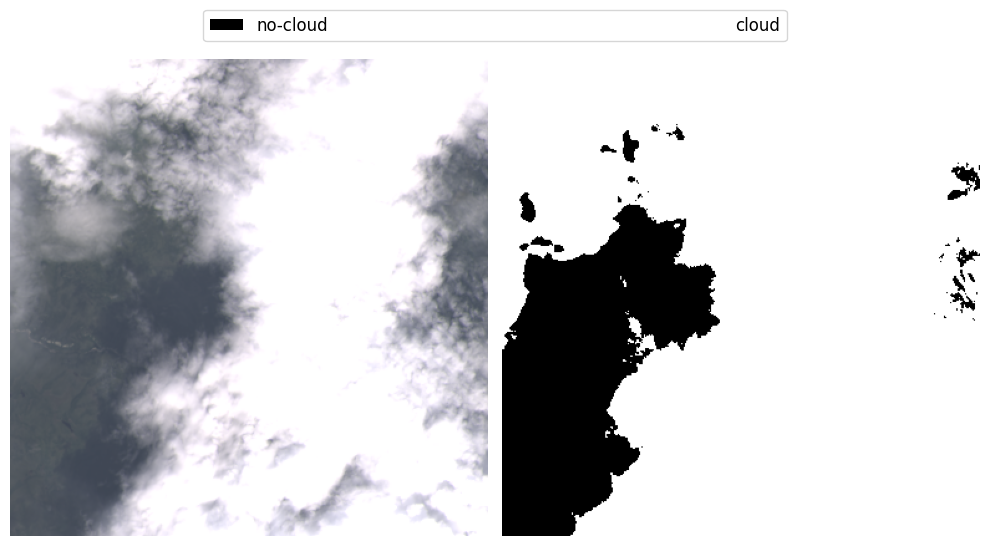

In [ ]:
dataset_config = {
    "data_dir": "./data/38cloud/train",
    "selection": "rgb"
}
dataset = Cloud38Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);
dataset.show_image(112);

In [32]:
dataset.data_distribution_table()

,Number of pixels
no-cloud,863885696.0
cloud,374744576.0


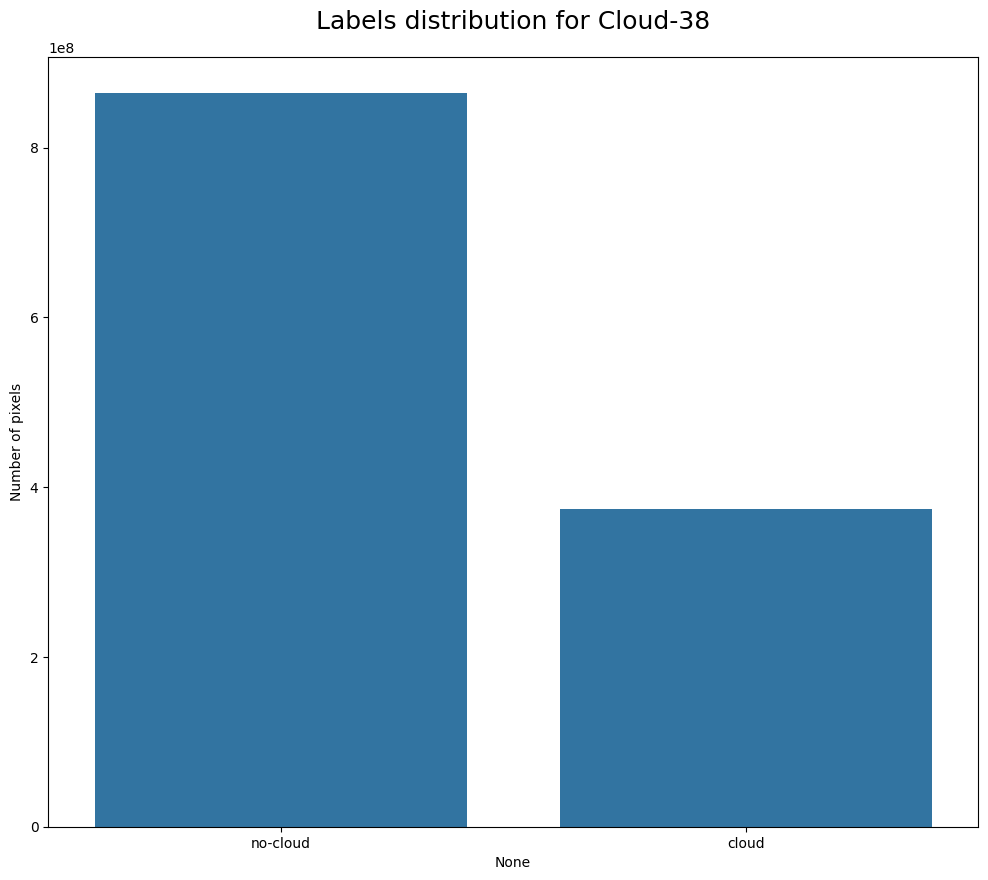

In [33]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 15,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/38cloud/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = Cloud38Dataset(train_dataset_config)
len(train_dataset)

8400

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/38cloud"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-07-17 06:37:36,308 INFO Starting training.
training: 100%|██████████| 560/560 [14:55<00:00,  1.60s/it]
2025-07-17 06:52:32,542 INFO epoch: 1, time: 896, loss:  0.25324
testing on train set: 100%|██████████| 560/560 [15:04<00:00,  1.62s/it]
2025-07-17 07:07:38,948 INFO IOU:0.7239032122432457, IOU mean:0.6661909392170069, IOU per Class:[0.80599703 0.52638485]
training: 100%|██████████| 560/560 [15:00<00:00,  1.61s/it]
2025-07-17 07:22:39,126 INFO epoch: 2, time: 901, loss:  0.18004
testing on train set: 100%|██████████| 560/560 [15:03<00:00,  1.61s/it]
2025-07-17 07:37:43,024 INFO IOU:0.7249563640497396, IOU mean:0.669262743631623, IOU per Class:[0.8062285  0.53229699]
training: 100%|██████████| 560/560 [14:56<00:00,  1.60s/it]
2025-07-17 07:52:39,771 INFO epoch: 3, time: 896, loss:  0.16511
testing on train set: 100%|██████████| 560/560 [14:57<00:00,  1.60s/it]
2025-07-17 08:07:37,364 INFO IOU:0.7423882462909573, IOU mean:0.6833241338153895, IOU per Class:[0.81691133 0.54973694]
tr

## Predictions

2025-07-17 11:45:55,401 INFO Loading checkpoint /home/dragik/data/FAIR_EO/38cloud/checkpoint.pth.tar
2025-07-17 11:45:55,777 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/38cloud/checkpoint.pth.tar at epoch 11
2025-07-17 11:45:55,821 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-07-17 11:45:55,921 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


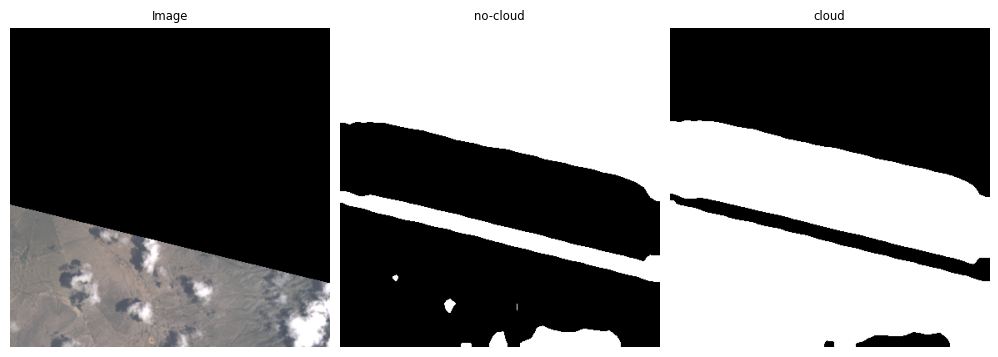

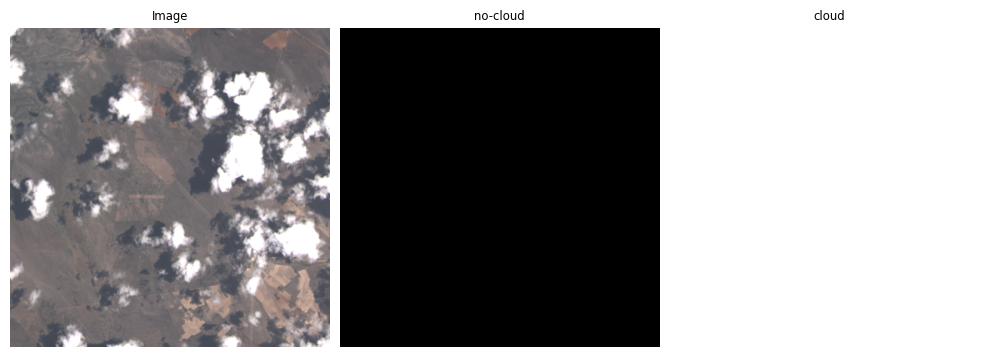

In [ ]:
model_path = "./data/38cloud/checkpoint.pth.tar"
labels = ["no-cloud","cloud"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})

imageB01 = image_loader('./data/38cloud/test/images/red/red_patch_6_1_by_6_LC08_L1TP_029041_20160720_20170222_01_T1.TIF')
imageB02 = image_loader('./data/38cloud/test/images/green/green_patch_6_1_by_6_LC08_L1TP_029041_20160720_20170222_01_T1.TIF')
imageB03 = image_loader('./data/38cloud/test/images/blue/blue_patch_6_1_by_6_LC08_L1TP_029041_20160720_20170222_01_T1.TIF')
image = np.dstack((imageB01,imageB02,imageB03))/25000
fig = model.predict_masks(image, labels, transform)

imageB01 = image_loader('./data/38cloud/test/images/red/red_patch_72_4_by_12_LC08_L1TP_029044_20160720_20170222_01_T1.TIF')
imageB02 = image_loader('./data/38cloud/test/images/green/green_patch_72_4_by_12_LC08_L1TP_029044_20160720_20170222_01_T1.TIF')
imageB03 = image_loader('./data/38cloud/test/images/blue/blue_patch_72_4_by_12_LC08_L1TP_029044_20160720_20170222_01_T1.TIF')
image = np.dstack((imageB01,imageB02,imageB03))/25000 
fig = model.predict_masks(image, labels, transform)